# Fase 2 — Desarrollo y modelado: ENT vs Determinantes Sociales (Cesar)

**Asignatura:** Inteligencia Artificial — Universidad Popular del Cesar
**Proyecto:** Predicción de riesgo de ENT asociadas a determinantes sociales en población dispersa
**Entrada:** `dataset_final_cesar_ent.csv` (25 municipios del Cesar)

El proyecto plantea una **tarea principal de regresión** (estimar la tasa de atenciones ENT por 1.000
habitantes) y una **variante de clasificación** (agrupar el riesgo en bajo/medio/alto). Este notebook cubre
las exigencias de la Fase 2: preprocesamiento, al menos dos modelos justificados, ajuste de hiperparámetros
documentado y evaluación cuantitativa comparativa.

**Decisión metodológica clave.** La variable objetivo está muy sesgada y contiene un valor atípico extremo
(Valledupar). Por eso los modelos de regresión se entrenan sobre el **logaritmo de la tasa**, lo que estabiliza
la varianza y mejora la bondad de ajuste (en la escala original, sin transformar, los modelos lineales
extrapolaban y fallaban). Las métricas se reportan en la escala logarítmica y, para la prueba, también en la
escala original.

**Aviso:** con solo **25 municipios** las métricas de un split fijo son muy inestables; por eso el análisis
principal se apoya en la **validación cruzada**. Los resultados son exploratorios.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, KFold, cross_validate, GridSearchCV)
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge
from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score,
    accuracy_score, f1_score, mean_absolute_error, r2_score, root_mean_squared_error)

sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

# Rutas del proyecto: resuelve la raiz sin importar desde donde se ejecute
from pathlib import Path
def _raiz_proyecto():
    for _p in [Path.cwd(), *Path.cwd().parents]:
        if (_p / "02_datos_procesados").is_dir() or (_p / "01_datos_originales").is_dir():
            return _p
    return Path.cwd()
BASE = _raiz_proyecto()
DIR_ORIG = BASE / "01_datos_originales"
DIR_PROC = BASE / "02_datos_procesados"


## 1. Carga y exploración inicial

In [2]:
df = pd.read_csv(DIR_PROC / "dataset_final_cesar_ent.csv", encoding="utf-8-sig")
print("Dimensiones:", df.shape)
print("Rango de la tasa total de atenciones ENT:",
      round(df["Tasa_Total_ENT_1000"].min(), 1), "-", round(df["Tasa_Total_ENT_1000"].max(), 1))
print("Poblacion total analizada:", int(df["Poblacion"].sum()), "habitantes")
display(df[["Cod_Mun", "Nom_Mun", "Poblacion", "Total_NBI_pct", "Tasa_Total_ENT_1000"]].head(10))

Dimensiones: (25, 35)
Rango de la tasa total de atenciones ENT: 320.9 - 3573.5
Poblacion total analizada: 1290919 habitantes


,Cod_Mun,Nom_Mun,Poblacion,Total_NBI_pct,Tasa_Total_ENT_1000
0,20001,VALLEDUPAR,526238.0,17.826291,3573.472459
1,20011,AGUACHICA,118392.0,18.794742,1514.131022
2,20013,AGUSTÍN CODAZZI,65428.0,28.666952,2799.382527
3,20032,ASTREA,21547.0,37.750895,634.844758
4,20045,BECERRIL,23265.0,35.523102,394.240275
5,20060,BOSCONIA,43191.0,31.771514,1834.363641
6,20175,CHIMICHAGUA,36683.0,30.371300,1274.922989
7,20178,CHIRIGUANÁ,29804.0,25.459668,1609.079318
8,20228,CURUMANÍ,40205.0,28.662475,982.688720
9,20238,EL COPEY,32335.0,26.984238,1081.490645


## 2. Ingeniería de características (preprocesamiento)

Además de los componentes NBI, se construyen tres variables derivadas que capturan el enfoque del proyecto
(brecha rural‑urbana y tamaño del municipio):

- `FE_Brecha_NBI_CPRD_Cabecera`: diferencia de NBI entre rural disperso y cabecera (desigualdad interna).
- `FE_Brecha_Miseria_CPRD_Cabecera`: diferencia de miseria entre rural disperso y cabecera.
- `FE_log_Poblacion`: logaritmo de la población (proxy del tamaño urbano y de la oferta de servicios).

También se verifica la relación de las variables con el **logaritmo** de la tasa objetivo.

In [3]:
df["FE_Brecha_NBI_CPRD_Cabecera"] = df["CPRD_NBI_pct"] - df["Cabecera_NBI_pct"]
df["FE_Brecha_Miseria_CPRD_Cabecera"] = df["CPRD_Miseria_pct"] - df["Cabecera_Miseria_pct"]
df["FE_log_Poblacion"] = np.log1p(df["Poblacion"])

fe_cols = ["FE_Brecha_NBI_CPRD_Cabecera", "FE_Brecha_Miseria_CPRD_Cabecera", "FE_log_Poblacion"]
print("Resumen de las nuevas variables:")
display(df[fe_cols].describe().T.round(3))

print("Correlacion con la tasa original y con log(tasa):")
base_tot = ["Total_NBI_pct", "Total_Miseria_pct", "Total_Servicios",
            "Total_Hacinamiento", "Poblacion"]
corr = pd.DataFrame({
    "corr_tasa": df[fe_cols + ["Total_NBI_pct"]].corrwith(df["Tasa_Total_ENT_1000"]),
    "corr_log_tasa": df[fe_cols + ["Total_NBI_pct"]].corrwith(np.log(df["Tasa_Total_ENT_1000"])),
})
display(corr.round(3))

Resumen de las nuevas variables:


,count,mean,std,min,25%,50%,75%,max
FE_Brecha_NBI_CPRD_Cabecera,25.0,12.274,15.690,-9.858,4.651,11.216,14.703,60.213
FE_Brecha_Miseria_CPRD_Cabecera,25.0,5.972,13.108,-8.751,1.580,2.862,6.733,52.941
FE_log_Poblacion,25.0,10.302,0.859,8.433,9.902,10.265,10.602,13.174


Correlacion con la tasa original y con log(tasa):


,corr_tasa,corr_log_tasa
FE_Brecha_NBI_CPRD_Cabecera,-0.071,-0.325
FE_Brecha_Miseria_CPRD_Cabecera,-0.203,-0.486
FE_log_Poblacion,0.285,0.188
Total_NBI_pct,-0.544,-0.712


## 3. Variables predictoras y variables objetivo

**Predictores (10).** Se usa un conjunto **curado y justificado por el dominio** para evitar la colinealidad
que desestabiliza los modelos lineales (los componentes de cabecera y rural disperso están fuertemente
correlacionados entre sí):

1. Los **7 componentes totales del NBI** (vivienda, servicios, hacinamiento, inasistencia, dependencia, NBI y miseria).
2. Las **2 brechas rural‑urbana** construidas (`FE_Brecha_NBI_CPRD_Cabecera`, `FE_Brecha_Miseria_CPRD_Cabecera`).
3. El **tamaño del municipio** (`FE_log_Poblacion`).

**Objetivos.**
- **Regresión (tarea principal):** `log(Tasa_Total_ENT_1000)`.
- **Clasificación (variante):** terciles de la tasa → `Bajo` / `Medio` / `Alto`.

In [4]:
predictores = [
    "Total_NBI_pct", "Total_Miseria_pct", "Total_Vivienda", "Total_Servicios",
    "Total_Hacinamiento", "Total_Inasistencia", "Total_Dependencia",
    "FE_Brecha_NBI_CPRD_Cabecera", "FE_Brecha_Miseria_CPRD_Cabecera", "FE_log_Poblacion",
]

X = df[predictores].copy()
y_reg = np.log(df["Tasa_Total_ENT_1000"])
y_clf = pd.qcut(df["Tasa_Total_ENT_1000"], q=3, labels=["Bajo", "Medio", "Alto"])
df["Categoria_Riesgo"] = y_clf

print("N de predictores:", len(predictores))
print("Distribucion de clases:", dict(y_clf.value_counts().reindex(["Bajo", "Medio", "Alto"])))

N de predictores: 10
Distribucion de clases: {'Bajo': np.int64(9), 'Medio': np.int64(8), 'Alto': np.int64(8)}


## 4. Partición de datos (70% entrenamiento / 15% validación / 15% prueba)

Partición **estratificada** por la clase de riesgo para conservar la proporción de cada nivel.

In [5]:
X_train, X_temp, y_train, y_temp, yc_train, yc_temp = train_test_split(
    X, y_reg, y_clf, test_size=0.30, stratify=y_clf, random_state=42)
X_val, X_test, y_val, y_test, yc_val, yc_test = train_test_split(
    X_temp, y_temp, yc_temp, test_size=0.50, stratify=yc_temp, random_state=42)

print("Entrenamiento:", X_train.shape[0], "| Validacion:", X_val.shape[0], "| Prueba:", X_test.shape[0])
print("Clases train:", dict(yc_train.value_counts()))
print("Clases val:  ", dict(yc_val.value_counts()))
print("Clases test: ", dict(yc_test.value_counts()))

Entrenamiento:

 17 | Validacion: 4 | Prueba: 4
Clases train: {'Bajo': np.int64(6), 'Medio': np.int64(6), 'Alto': np.int64(5)}
Clases val:   {'Bajo': np.int64(2), 'Medio': np.int64(1), 'Alto': np.int64(1)}
Clases test:  {'Alto': np.int64(2), 'Bajo': np.int64(1), 'Medio': np.int64(1)}


## 5. Estrategia de validación cruzada

`KFold` (regresión) y `StratifiedKFold` (clasificación), ambos con k=5, y ayudantes para resumir métricas.

In [6]:
cv_reg = KFold(n_splits=5, shuffle=True, random_state=42)
cv_clf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def cv_regresion(estimador, X, y, cv=cv_reg):
    r = cross_validate(estimador, X, y, cv=cv, scoring=[
        "r2", "neg_root_mean_squared_error", "neg_mean_absolute_error"])
    return {"R2": r["test_r2"].mean(),
            "RMSE_log": -r["test_neg_root_mean_squared_error"].mean(),
            "MAE_log": -r["test_neg_mean_absolute_error"].mean()}

def cv_clasificacion(estimador, X, y, cv=cv_clf):
    r = cross_validate(estimador, X, y, cv=cv, scoring=["accuracy", "f1_macro"])
    return {"accuracy": r["test_accuracy"].mean(), "f1_macro": r["test_f1_macro"].mean()}

## 6. Tarea principal — Regresión de la tasa de atenciones ENT

Se comparan: un **baseline** (predice la media del log de la tasa), una **regresión regularizada (Ridge)** —
modelo lineal interpretable que controla la multicolinealidad y el sobreajuste — y un **Gradient Boosting
Regressor** con ajuste de hiperparámetros. Todos con `StandardScaler` y validación cruzada k‑5.

### 6.1 Modelos lineales (regresión múltiple y Ridge) con ajuste de `alpha`

In [7]:
dummy = DummyRegressor(strategy="mean")

pipe_ols = Pipeline([
    ("prep", ColumnTransformer([("num", StandardScaler(), predictores)])),
    ("reg", LinearRegression())])

pipe_ridge = Pipeline([
    ("prep", ColumnTransformer([("num", StandardScaler(), predictores)])),
    ("reg", Ridge())])
gs_ridge = GridSearchCV(pipe_ridge, {"reg__alpha": [0.01, 0.1, 1, 10, 100, 1000, 10000]},
                        cv=cv_reg, scoring="r2", n_jobs=1)
gs_ridge.fit(X, y_reg)
mejor_ridge = gs_ridge.best_estimator_

print("Baseline (media)        :", {k: round(v, 3) for k, v in cv_regresion(dummy, X, y_reg).items()})
print("Regresion lineal (OLS)  :", {k: round(v, 3) for k, v in cv_regresion(pipe_ols, X, y_reg).items()})
print("Ridge (alpha =", gs_ridge.best_params_["reg__alpha"], ") :",
      {k: round(v, 3) for k, v in cv_regresion(mejor_ridge, X, y_reg).items()})

Baseline (media)        : {'R2': np.float64(-0.09), 'RMSE_log': np.float64(0.53), 'MAE_log': np.float64(0.425)}
Regresion lineal (OLS)  : {'R2': np.float64(-1.562), 'RMSE_log': np.float64(0.663), 'MAE_log': np.float64(0.545)}
Ridge (alpha = 100 ) : {'R2': np.float64(0.042), 'RMSE_log': np.float64(0.437), 'MAE_log': np.float64(0.369)}


### 6.2 Coeficientes de la regresión Ridge (interpretabilidad)

In [8]:
mejor_ridge.fit(X_train, y_train)
coef = pd.Series(mejor_ridge.named_steps["reg"].coef_, index=predictores)
coef = coef.sort_values(key=np.abs, ascending=False)
print("Coeficientes estandarizados (asociacion con log de la tasa):")
print(coef.round(3).to_string())

Coeficientes estandarizados (asociacion con log de la tasa):
Total_Vivienda                    -0.040
Total_NBI_pct                     -0.034
Total_Miseria_pct                 -0.031
FE_log_Poblacion                   0.027
Total_Servicios                   -0.022
Total_Hacinamiento                -0.022
Total_Inasistencia                 0.017
Total_Dependencia                 -0.016
FE_Brecha_Miseria_CPRD_Cabecera   -0.012
FE_Brecha_NBI_CPRD_Cabecera       -0.003


### 6.3 Gradient Boosting Regressor + ajuste de hiperparámetros

Búsqueda en rejilla (`GridSearchCV`, 5 particiones) sobre número de árboles, tasa de aprendizaje y profundidad.

In [9]:
pipe_gbr = Pipeline([
    ("prep", ColumnTransformer([("num", StandardScaler(), predictores)])),
    ("reg", GradientBoostingRegressor(random_state=42))])

grid_gbr = {"reg__n_estimators": [50, 100, 200],
            "reg__learning_rate": [0.01, 0.05, 0.1],
            "reg__max_depth": [1, 2, 3]}
gs_gbr = GridSearchCV(pipe_gbr, grid_gbr, cv=cv_reg, scoring="r2", n_jobs=1)
gs_gbr.fit(X, y_reg)
mejor_gbr = gs_gbr.best_estimator_

print("Mejores hiperparametros (GBRegressor):", gs_gbr.best_params_)
print("CV completa (todos los datos):", {k: round(v, 3) for k, v in cv_regresion(mejor_gbr, X, y_reg).items()})

Mejores hiperparametros (GBRegressor): {'reg__learning_rate': 0.01, 'reg__max_depth': 2, 'reg__n_estimators': 50}
CV completa (todos los datos): {'R2': np.float64(0.037), 'RMSE_log': np.float64(0.474), 'MAE_log': np.float64(0.391)}


## 6.4 Comparación de los modelos de regresión (métricas en escala log)

In [10]:
modelos_reg = {
    "Dummy (media)": dummy,
    "Regresion lineal (OLS)": pipe_ols,
    "Ridge (regularizada)": mejor_ridge,
    "Gradient Boosting": mejor_gbr,
}
filas = []
for nombre, m in modelos_reg.items():
    cvr = cv_regresion(m, X, y_reg)
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    filas.append({"Modelo": nombre,
                  "CV_R2": cvr["R2"], "CV_RMSE_log": cvr["RMSE_log"], "CV_MAE_log": cvr["MAE_log"],
                  "Test_R2_log": r2_score(y_test, pred),
                  "Test_RMSE_log": root_mean_squared_error(y_test, pred),
                  "Test_MAE_log": mean_absolute_error(y_test, pred)})
tabla_reg = pd.DataFrame(filas).set_index("Modelo")
display(tabla_reg.round(3))

,CV_R2,CV_RMSE_log,CV_MAE_log,Test_R2_log,Test_RMSE_log,Test_MAE_log
Modelo,,,,,,
Dummy (media),-0.090,0.530,0.425,-0.079,0.437,0.370
Regresion lineal (OLS),-1.562,0.663,0.545,-0.193,0.459,0.391
Ridge (regularizada),0.042,0.437,0.369,-0.079,0.437,0.396
Gradient Boosting,0.037,0.474,0.391,-0.197,0.460,0.409


,Municipio,Observado,Predicho_GBR
0,GONZÁLEZ,2714.0,1539.0
1,BOSCONIA,1834.0,1095.0
2,PELAYA,1475.0,1407.0
3,LA GLORIA,848.0,1407.0


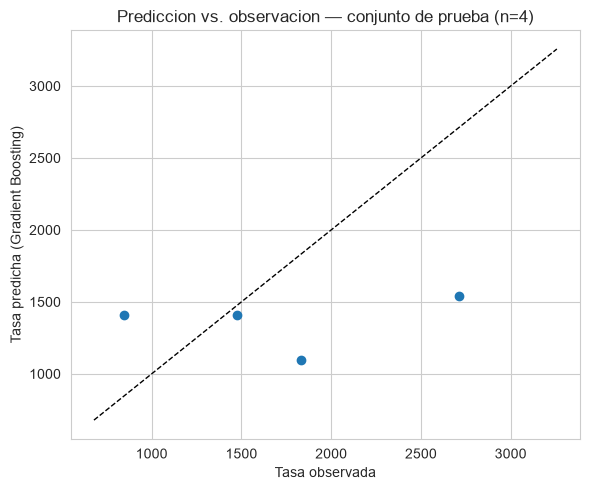

In [11]:
# Predicciones en la escala original (atenciones por 1.000 habitantes) para la prueba
pred_orig = np.exp(mejor_gbr.predict(X_test))
real_orig = np.exp(y_test)
comp = pd.DataFrame({"Municipio": df.loc[X_test.index, "Nom_Mun"].values,
                     "Observado": real_orig.values, "Predicho_GBR": pred_orig}).round(0)
display(comp)

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(real_orig, pred_orig, color="#1f77b4")
lims = [real_orig.min() * 0.8, real_orig.max() * 1.2]
ax.plot(lims, lims, "k--", lw=1)
ax.set_xlabel("Tasa observada"); ax.set_ylabel("Tasa predicha (Gradient Boosting)")
ax.set_title("Prediccion vs. observacion — conjunto de prueba (n=4)")
plt.tight_layout(); plt.show()

## 7. Variante de clasificación (bajo / medio / alto)

Se entrenan una **Regresión Logística Multinomial** (interpretable) y un **Gradient Boosting Classifier**
(poder predictivo), ambos con ajuste de hiperparámetros. Dado el reducido tamaño muestral, se espera un
desempeño modesto; se reporta honestamente como resultado exploratorio.

### 7.1 Regresión Logística + ajuste de `C`

In [12]:
pipe_lr = Pipeline([
    ("prep", ColumnTransformer([("num", StandardScaler(), predictores)])),
    ("clf", LogisticRegression(solver="lbfgs", max_iter=5000, random_state=42))])
gs_lr = GridSearchCV(pipe_lr, {"clf__C": [0.01, 0.1, 1, 10, 100]},
                     cv=cv_clf, scoring="f1_macro", n_jobs=1)
gs_lr.fit(X, y_clf)
mejor_lr = gs_lr.best_estimator_
print("Mejor C:", gs_lr.best_params_)
print("CV:", {k: round(v, 3) for k, v in cv_clasificacion(mejor_lr, X, y_clf).items()})

Mejor C: {'clf__C': 100}
CV: {'accuracy': np.float64(0.32), 'f1_macro': np.float64(0.293)}


### 7.2 Gradient Boosting Classifier + ajuste de hiperparámetros

In [13]:
pipe_gbc = Pipeline([
    ("prep", ColumnTransformer([("num", StandardScaler(), predictores)])),
    ("clf", GradientBoostingClassifier(random_state=42))])
grid_gbc = {"clf__n_estimators": [50, 100, 200],
            "clf__learning_rate": [0.01, 0.05, 0.1],
            "clf__max_depth": [1, 2, 3]}
gs_gbc = GridSearchCV(pipe_gbc, grid_gbc, cv=cv_clf, scoring="f1_macro", n_jobs=1)
gs_gbc.fit(X, y_clf)
mejor_gbc = gs_gbc.best_estimator_
print("Mejores hiperparametros (GBClassifier):", gs_gbc.best_params_)
print("CV:", {k: round(v, 3) for k, v in cv_clasificacion(mejor_gbc, X, y_clf).items()})

Mejores hiperparametros (GBClassifier): {'clf__learning_rate': 0.01, 'clf__max_depth': 3, 'clf__n_estimators': 100}


CV: {'accuracy': np.float64(0.44), 'f1_macro': np.float64(0.416)}


### 7.3 Evaluación en el conjunto de prueba (matriz de confusión, F1 y ROC‑AUC)

In [14]:
evaluaciones = {}
for nombre, m in [("Regresion Logistica", mejor_lr), ("Gradient Boosting", mejor_gbc)]:
    m.fit(X_train, yc_train)
    y_pred = m.predict(X_test)
    proba = m.predict_proba(X_test)
    labels = m.named_steps["clf"].classes_
    evaluaciones[nombre] = dict(y_pred=y_pred)
    print("=" * 60)
    print(nombre, "- CONJUNTO DE PRUEBA")
    print("=" * 60)
    print(classification_report(yc_test, y_pred, labels=["Bajo", "Medio", "Alto"], zero_division=0))
    print("Matriz de confusion (filas=real, columnas=predicho; orden Bajo/Medio/Alto):")
    print(confusion_matrix(yc_test, y_pred, labels=["Bajo", "Medio", "Alto"]))
    print("ROC-AUC macro (one-vs-rest):",
          round(roc_auc_score(yc_test, proba, multi_class="ovr", average="macro", labels=labels), 3))
    print()

Regresion Logistica - CONJUNTO DE PRUEBA
              precision    recall  f1-score   support

        Bajo       0.00      0.00      0.00         1
       Medio       0.33      1.00      0.50         1
        Alto       1.00      0.50      0.67         2

    accuracy                           0.50         4
   macro avg       0.44      0.50      0.39         4
weighted avg       0.58      0.50      0.46         4

Matriz de confusion (filas=real, columnas=predicho; orden Bajo/Medio/Alto):
[[0 1 0]
 [0 1 0]
 [0 1 1]]
ROC-AUC macro (one-vs-rest): 0.389



Gradient Boosting - CONJUNTO DE PRUEBA
              precision    recall  f1-score   support

        Bajo       0.00      0.00      0.00         1
       Medio       0.50      1.00      0.67         1
        Alto       1.00      0.50      0.67         2

    accuracy                           0.50         4
   macro avg       0.50      0.50      0.44         4
weighted avg       0.62      0.50      0.50         4

Matriz de confusion (filas=real, columnas=predicho; orden Bajo/Medio/Alto):
[[0 1 0]
 [0 1 0]
 [1 0 1]]
ROC-AUC macro (one-vs-rest): 0.389



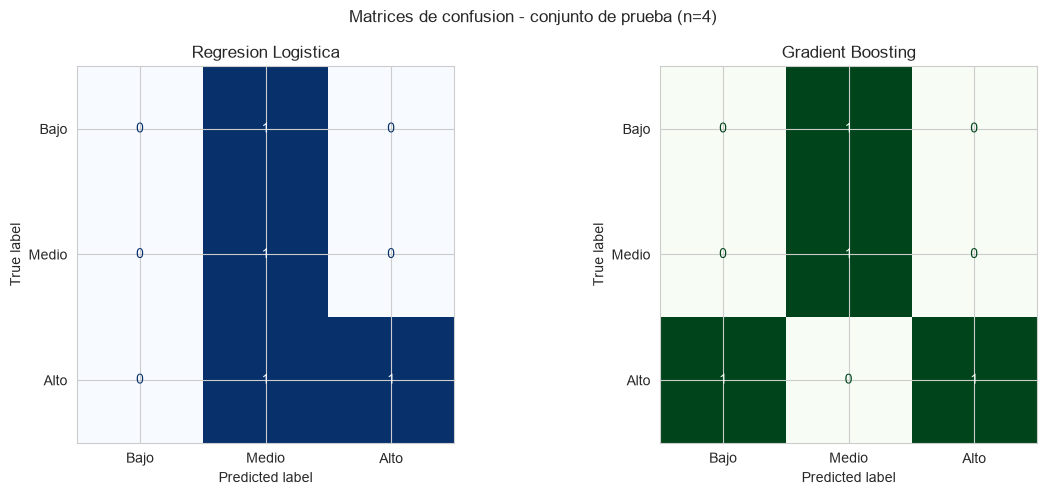

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, nombre, cmap in zip(axes, ["Regresion Logistica", "Gradient Boosting"], ["Blues", "Greens"]):
    cm = confusion_matrix(yc_test, evaluaciones[nombre]["y_pred"], labels=["Bajo", "Medio", "Alto"])
    ConfusionMatrixDisplay(cm, display_labels=["Bajo", "Medio", "Alto"]).plot(
        ax=ax, cmap=cmap, values_format="d", colorbar=False)
    ax.set_title(nombre)
plt.suptitle("Matrices de confusion - conjunto de prueba (n=4)")
plt.tight_layout(); plt.show()

### 7.4 Comparación de los modelos de clasificación

In [16]:
filas = []
for nombre, m in [("Regresion Logistica", mejor_lr), ("Gradient Boosting", mejor_gbc)]:
    cvr = cv_clasificacion(m, X, y_clf)
    m.fit(X_train, yc_train)
    y_pred = m.predict(X_test)
    proba = m.predict_proba(X_test)
    labels = m.named_steps["clf"].classes_
    filas.append({"Modelo": nombre,
                  "CV_accuracy": cvr["accuracy"], "CV_f1_macro": cvr["f1_macro"],
                  "Test_accuracy": accuracy_score(yc_test, y_pred),
                  "Test_f1_macro": f1_score(yc_test, y_pred, average="macro"),
                  "Test_ROC_AUC": roc_auc_score(yc_test, proba, multi_class="ovr",
                                                average="macro", labels=labels)})
display(pd.DataFrame(filas).set_index("Modelo").round(3))

,CV_accuracy,CV_f1_macro,Test_accuracy,Test_f1_macro,Test_ROC_AUC
Modelo,,,,,
Regresion Logistica,0.32,0.293,0.5,0.389,0.389
Gradient Boosting,0.44,0.416,0.5,0.444,0.389


## 8. Conclusiones y limitaciones

- Se cubren las exigencias de la Fase 2: **preprocesamiento** (limpieza, estandarización, ingeniería de
  características y partición 70/15/15), **dos modelos por tarea** (lineal/regularizado e interpretable vs.
  Gradient Boosting) y **ajuste de hiperparámetros** con validación cruzada documentado.
- **Transformar la tasa con logaritmo** fue determinante: en la escala original los modelos lineales
  extrapolaban frente a Valledupar y arrojaban R² de validación muy negativos; en la escala log el ajuste es
  estable y comparable.
- La **regresión** es la tarea mejor comportada; la **clasificación en terciles** apenas supera el azar en
  validación cruzada (3 clases ≈ 0.33), lo que indica una señal débil con n=25.
- **Relación negativa NBI–tasa:** los municipios con mayor NBI tienden a registrar *menos* atenciones por ENT.
  Esto es coherente con un **sesgo de detección/acceso** (menos diagnóstico donde hay menos servicios), no con
  una menor enfermedad real. Es la principal advertencia interpretativa del proyecto.
- **Limitaciones:** n=25, valor atípico dominante (Valledupar), y la tasa mide en parte oferta/acceso.
- **Trabajo futuro:** ampliar la unidad de análisis a municipio × año, tratar el valor atípico (winsorización
  o modelos robustos) y usar validación cruzada repetida.